### Project Name: Student Performance Predictor
### Models: Linear Regression and Logistic Regression

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:

url = "https://raw.githubusercontent.com/rupakc/UCI-Data-Analysis/master/Student%20Dataset/Student/student-mat.csv"

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [6]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nFinal grade statistics:")
print(df["G3"].describe())


Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardi

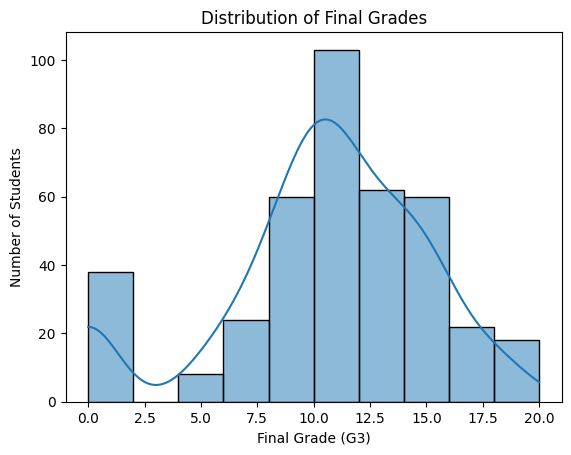

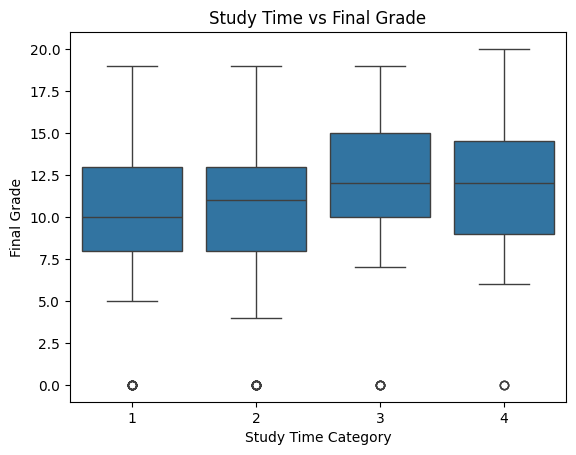

In [7]:

# Graph 1: Distribution of final grades
sns.histplot(df["G3"], bins=10, kde=True)
plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()

# Graph 2: Study time and final grades
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade")
plt.show()


In [8]:

# Select the input features
X = df[["studytime", "absences", "G1", "G2"]]

# Target for marks prediction
y_marks = df["G3"]

# Target for pass/fail classification
y_pass = (df["G3"] >= 10).astype(int)

# Split the data into training and testing sets
X_train, X_test, y_marks_train, y_marks_test, y_pass_train, y_pass_test = train_test_split(
    X, y_marks, y_pass,
    test_size=0.20,
    random_state=42
)

# Handle missing values using training data
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Preprocessing completed!")


Training records: 316
Testing records: 79
Preprocessing completed!


In [9]:

linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_model.fit(X_train, y_marks_train)

print("Linear Regression trained successfully!")


Linear Regression trained successfully!


In [10]:

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

logistic_model.fit(X_train, y_pass_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [11]:

marks_predictions = linear_model.predict(X_test)

r2 = r2_score(y_marks_test, marks_predictions)
mae = mean_absolute_error(y_marks_test, marks_predictions)

print("Linear Regression Results")
print("R-squared (R²):", round(r2, 3))
print("Mean Absolute Error:", round(mae, 3))


Linear Regression Results
R-squared (R²): 0.796
Mean Absolute Error: 1.313


In [12]:

pass_predictions = logistic_model.predict(X_test)

accuracy = accuracy_score(y_pass_test, pass_predictions)
precision = precision_score(y_pass_test, pass_predictions, zero_division=0)
recall = recall_score(y_pass_test, pass_predictions, zero_division=0)

print("Logistic Regression Results")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))

print("\nClassification Report:")
print(classification_report(
    y_pass_test,
    pass_predictions,
    target_names=["Fail", "Pass"],
    zero_division=0
))


Logistic Regression Results
Accuracy: 89.87 %
Precision: 0.958
Recall: 0.885

Classification Report:
              precision    recall  f1-score   support

        Fail       0.81      0.93      0.86        27
        Pass       0.96      0.88      0.92        52

    accuracy                           0.90        79
   macro avg       0.88      0.91      0.89        79
weighted avg       0.91      0.90      0.90        79



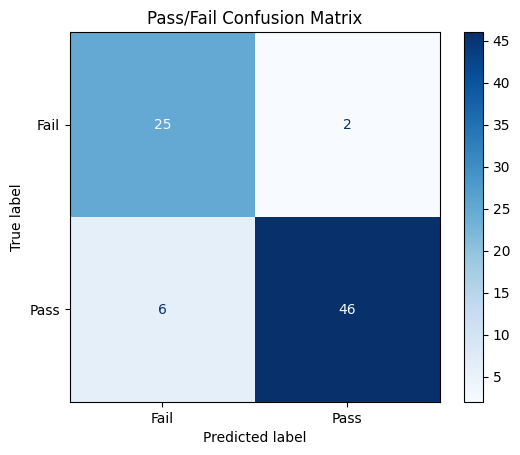

In [13]:

cm = confusion_matrix(y_pass_test, pass_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
).plot(cmap="Blues")

plt.title("Pass/Fail Confusion Matrix")
plt.show()


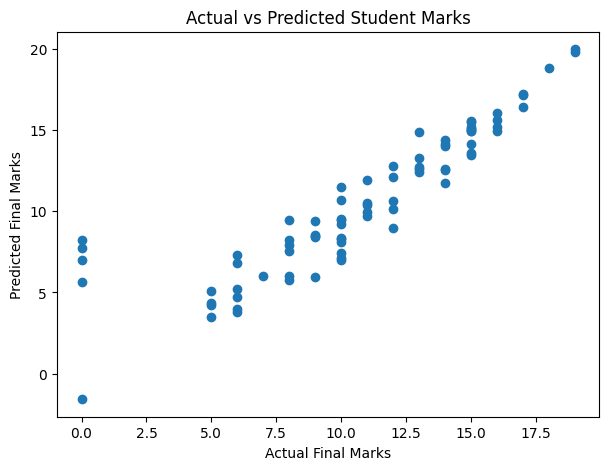

In [14]:

plt.figure(figsize=(7, 5))

plt.scatter(y_marks_test, marks_predictions)

plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")
plt.title("Actual vs Predicted Student Marks")

plt.show()


In [15]:

print("FINAL PROJECT RESULTS")
print("---------------------")

print("Linear Regression R²:", round(r2, 3))
print("Linear Regression MAE:", round(mae, 3))

print("Logistic Regression Accuracy:",
      round(accuracy * 100, 2), "%")

print("Logistic Regression Precision:", round(precision, 3))
print("Logistic Regression Recall:", round(recall, 3))

print("\nConclusion:")
print("Linear Regression predicts students' final marks.")
print("Logistic Regression predicts Pass or Fail.")
print("Both models were evaluated using appropriate metrics.")


FINAL PROJECT RESULTS
---------------------
Linear Regression R²: 0.796
Linear Regression MAE: 1.313
Logistic Regression Accuracy: 89.87 %
Logistic Regression Precision: 0.958
Logistic Regression Recall: 0.885

Conclusion:
Linear Regression predicts students' final marks.
Logistic Regression predicts Pass or Fail.
Both models were evaluated using appropriate metrics.


In [16]:

# Example student:
# Study time: 3, Absences: 2, G1: 12, G2: 14

new_student = pd.DataFrame({
    "studytime": [3],
    "absences": [2],
    "G1": [12],
    "G2": [14]
})

predicted_marks = linear_model.predict(new_student)[0]
predicted_result = logistic_model.predict(new_student)[0]

print("Predicted Final Marks:", round(predicted_marks, 2), "out of 20")

if predicted_result == 1:
    print("Predicted Result: PASS")
else:
    print("Predicted Result: FAIL")


Predicted Final Marks: 13.64 out of 20
Predicted Result: PASS
